In [1]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import time

print("Smart City Traffic Management System")
print("All libraries imported successfully!")

Smart City Traffic Management System
All libraries imported successfully!


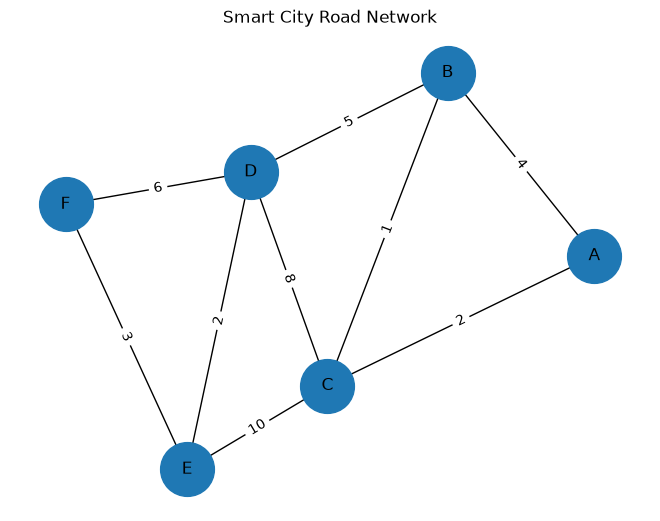

Total intersections: 6
Total roads: 9


In [2]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

roads = [
    ("A", "B", 4),
    ("A", "C", 2),
    ("B", "C", 1),
    ("B", "D", 5),
    ("C", "D", 8),
    ("C", "E", 10),
    ("D", "E", 2),
    ("D", "F", 6),
    ("E", "F", 3)
]

G.add_weighted_edges_from(roads)

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G, pos, with_labels=True,
    node_size=1500, font_size=12
)

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=nx.get_edge_attributes(G, "weight")
)

plt.title("Smart City Road Network")
plt.show()

print("Total intersections:", G.number_of_nodes())
print("Total roads:", G.number_of_edges())

Source: A
Destination: F
Shortest Route: A -> C -> B -> D -> E -> F
Total Distance: 13


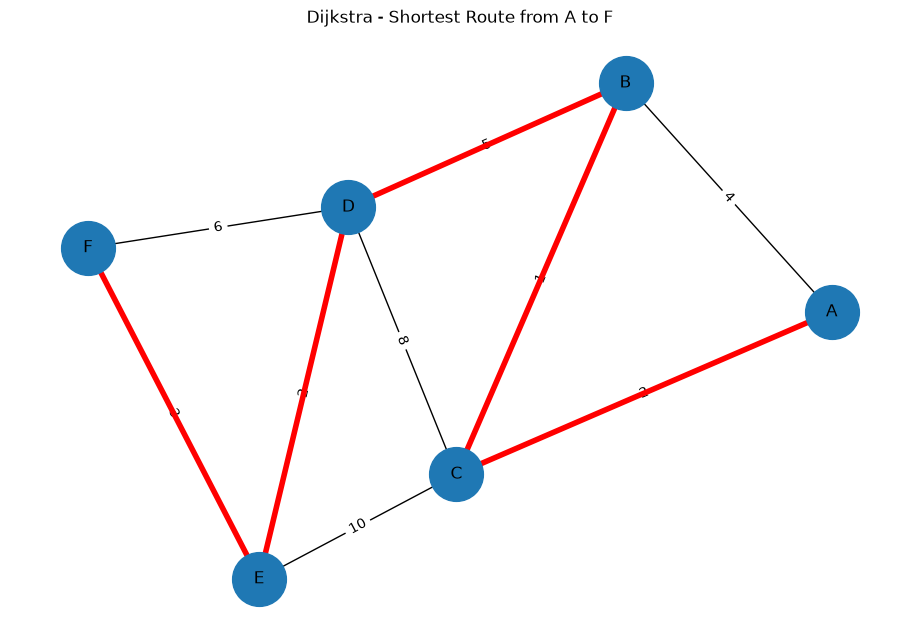

In [3]:
source = "A"
destination = "F"

shortest_route = nx.dijkstra_path(
    G, source, destination, weight="weight"
)

distance = nx.dijkstra_path_length(
    G, source, destination, weight="weight"
)

print("Source:", source)
print("Destination:", destination)
print("Shortest Route:", " -> ".join(shortest_route))
print("Total Distance:", distance)

route_edges = list(zip(shortest_route, shortest_route[1:]))

plt.figure(figsize=(9, 6))

nx.draw(
    G, pos, with_labels=True,
    node_size=1500, font_size=12
)

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=nx.get_edge_attributes(G, "weight")
)

nx.draw_networkx_edges(
    G, pos, edgelist=route_edges,
    edge_color="red", width=4
)

plt.title("Dijkstra - Shortest Route from A to F")
plt.show()

In [4]:
G_traffic = G.copy()

# Road B-D par traffic ki wajah se extra cost
G_traffic["B"]["D"]["weight"] += 10

# Original shortest route
original_route = nx.bellman_ford_path(
    G, "A", "F", weight="weight"
)
original_cost = nx.bellman_ford_path_length(
    G, "A", "F", weight="weight"
)

# Traffic ke baad shortest route
traffic_route = nx.bellman_ford_path(
    G_traffic, "A", "F", weight="weight"
)
traffic_cost = nx.bellman_ford_path_length(
    G_traffic, "A", "F", weight="weight"
)

print("BEFORE TRAFFIC")
print("Route:", " -> ".join(original_route))
print("Total Cost:", original_cost)

print("\nAFTER TRAFFIC")
print("Route:", " -> ".join(traffic_route))
print("Total Cost:", traffic_cost)

BEFORE TRAFFIC
Route: A -> C -> B -> D -> E -> F
Total Cost: 13

AFTER TRAFFIC
Route: A -> C -> E -> F
Total Cost: 15


In [5]:
# BFS Traversal
bfs_nodes = list(nx.bfs_tree(G, source="A").nodes())

# DFS Traversal
dfs_nodes = list(nx.dfs_tree(G, source="A").nodes())

print("BFS Traversal:", " -> ".join(bfs_nodes))
print("DFS Traversal:", " -> ".join(dfs_nodes))

# Check network connectivity
print("Is Network Connected?", nx.is_connected(G))
print("Total Intersections:", G.number_of_nodes())
print("Total Roads:", G.number_of_edges())

BFS Traversal: A -> B -> C -> D -> E -> F
DFS Traversal: A -> B -> C -> D -> E -> F
Is Network Connected? True
Total Intersections: 6
Total Roads: 9


Prim MST Edges: [('A', 'C', 2), ('B', 'D', 5), ('B', 'C', 1), ('D', 'E', 2), ('E', 'F', 3)]
Prim MST Total Cost: 13.0

Kruskal MST Edges: [('A', 'C', 2), ('B', 'C', 1), ('B', 'D', 5), ('D', 'E', 2), ('E', 'F', 3)]
Kruskal MST Total Cost: 13.0


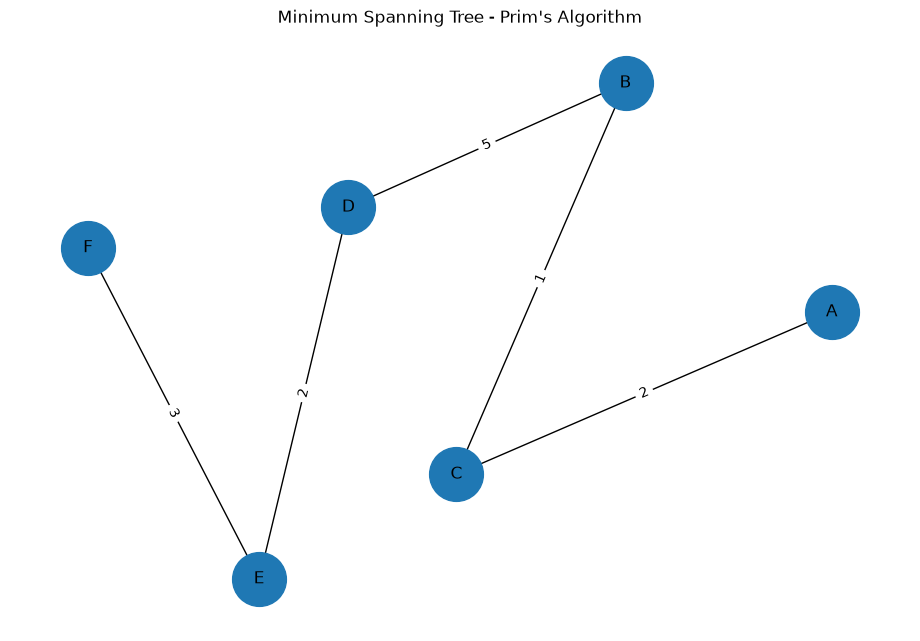

In [6]:
# Prim's Algorithm
mst_prim = nx.minimum_spanning_tree(
    G, algorithm="prim", weight="weight"
)

# Kruskal's Algorithm
mst_kruskal = nx.minimum_spanning_tree(
    G, algorithm="kruskal", weight="weight"
)

print("Prim MST Edges:", list(mst_prim.edges(data="weight")))
print("Prim MST Total Cost:", mst_prim.size(weight="weight"))

print("\nKruskal MST Edges:", list(mst_kruskal.edges(data="weight")))
print("Kruskal MST Total Cost:", mst_kruskal.size(weight="weight"))

# Visualize MST
plt.figure(figsize=(9, 6))

nx.draw(
    mst_prim,
    pos,
    with_labels=True,
    node_size=1500,
    font_size=12
)

nx.draw_networkx_edge_labels(
    mst_prim,
    pos,
    edge_labels=nx.get_edge_attributes(mst_prim, "weight")
)

plt.title("Minimum Spanning Tree - Prim's Algorithm")
plt.show()

,Intersections,Algorithm,Execution Time (ms)
0,10,BFS,0.1203
1,10,DFS,0.0883
2,10,Dijkstra,0.1305
3,10,Bellman-Ford,0.1421
4,10,Prim,0.2586
5,10,Kruskal,0.2572
6,25,BFS,0.1372
7,25,DFS,0.1137
8,25,Dijkstra,0.0853
9,25,Bellman-Ford,0.2009


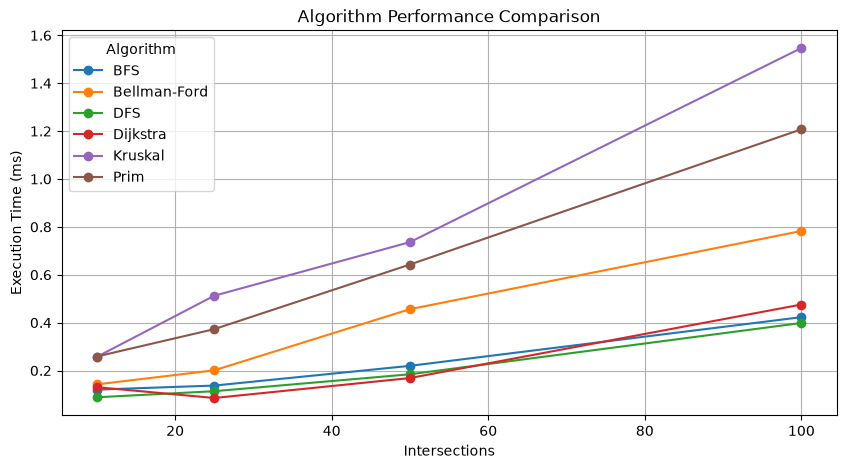

In [7]:
import time

sizes = [10, 25, 50, 100]
results = []

for n in sizes:
    graph = nx.gnm_random_graph(n, min(n * 3, n * (n - 1) // 2), seed=42)

    # Ensure the graph is connected
    components = list(nx.connected_components(graph))
    for i in range(len(components) - 1):
        u = next(iter(components[i]))
        v = next(iter(components[i + 1]))
        graph.add_edge(u, v)

    for u, v in graph.edges():
        graph[u][v]["weight"] = 1 + (u + v) % 20

    algorithms = {
        "BFS": lambda: list(nx.bfs_tree(graph, 0)),
        "DFS": lambda: list(nx.dfs_tree(graph, 0)),
        "Dijkstra": lambda: nx.dijkstra_path(graph, 0, n - 1, weight="weight"),
        "Bellman-Ford": lambda: nx.bellman_ford_path(graph, 0, n - 1, weight="weight"),
        "Prim": lambda: nx.minimum_spanning_tree(graph, algorithm="prim", weight="weight"),
        "Kruskal": lambda: nx.minimum_spanning_tree(graph, algorithm="kruskal", weight="weight")
    }

    for name, algorithm in algorithms.items():
        start = time.perf_counter()
        algorithm()
        elapsed = (time.perf_counter() - start) * 1000

        results.append({
            "Intersections": n,
            "Algorithm": name,
            "Execution Time (ms)": round(elapsed, 4)
        })

df = pd.DataFrame(results)

display(df)

df.pivot(
    index="Intersections",
    columns="Algorithm",
    values="Execution Time (ms)"
).plot(
    marker="o",
    figsize=(10, 5),
    title="Algorithm Performance Comparison"
)

plt.ylabel("Execution Time (ms)")
plt.grid(True)
plt.show()